# Confidence Intervals for Action Rules

Action rules tell us *what to change* to move from an undesired outcome to a desired one. But how confident can we be in those recommendations? A rule mined from a sample might look promising, yet its true effect could be much smaller — or even zero.

This notebook demonstrates the **confidence interval** module of the `action-rules` package. It covers:

1. **Mining action rules** on the Telco Customer Churn dataset
2. **Five CI variants**: Bootstrap Percentile, Bootstrap BCa, Analytic (Wald), Analytic (Wilson), and Bayesian
3. **Rule categorization**: Accept, Reject, or Uncertain
4. **Distribution visualization**: comparing all five methods for a single rule
5. **Forest plots**: single-method and grouped (all five methods)
6. **Utility-aware analysis**: confidence intervals for realistic rule gain

**Requirements**: `pip install action-rules[viz]` (adds scipy + matplotlib)

## 1. Setup and Data Loading

We use the **Telco Customer Churn** dataset (~7,000 customers). The goal: find actionable interventions that reduce churn. Each row is a customer with attributes like contract type, internet service, and whether they churned.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Load the Telco Customer Churn dataset
data = pd.read_csv("data/telco.csv", sep=";")
print(f"Dataset: {data.shape[0]} customers, {data.shape[1]} attributes")
data.head(3)

Dataset: 7043 customers, 21 attributes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Mining Action Rules

We define **stable attributes** (conditions that describe a customer segment, e.g., gender, senior citizen status) and **flexible attributes** (things the company can change, e.g., contract type, tech support). The target is `Churn` — we want rules that move customers from `Yes` (churning) to `No` (retained).

We also define **utility tables** to quantify the economic value of each state and transition. This lets us compute not just statistical uplift but also the *realistic monetary gain* of applying each rule.

In [2]:
from action_rules import ActionRules

# Attributes
stable_attributes = ["gender", "SeniorCitizen", "Partner"]
flexible_attributes = [
    "PhoneService",
    "InternetService",
    "OnlineSecurity",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
]

# Utility tables: how much is each state worth economically?
intrinsic_utility_table = {
    # Retaining a customer is worth $400 (lifetime value), losing one costs nothing extra
    ("Churn", "No"): 400.0,
    ("Churn", "Yes"): 0.0,
    # Service costs (monthly impact)
    ("OnlineSecurity", "Yes"): -10.0,
    ("OnlineSecurity", "No"): 0.0,
    ("DeviceProtection", "Yes"): -8.0,
    ("DeviceProtection", "No"): 0.0,
    ("TechSupport", "Yes"): -12.0,
    ("TechSupport", "No"): 0.0,
    ("StreamingTV", "Yes"): -5.0,
    ("StreamingTV", "No"): 0.0,
}

transition_utility_table = {
    # Cost of upgrading a service for a customer
    ("OnlineSecurity", "No", "Yes"): -5.0,
    ("DeviceProtection", "No", "Yes"): -4.0,
    ("TechSupport", "No", "Yes"): -6.0,
    ("StreamingTV", "No", "Yes"): -3.0,
}

# Initialize the action rules miner
# We use slightly relaxed confidence (0.68) to get a meaningful set of rules for demonstration
ar = ActionRules(
    min_stable_attributes=3,
    min_flexible_attributes=5,
    min_undesired_support=20,
    min_undesired_confidence=0.56,
    min_desired_support=10,
    min_desired_confidence=0.6,
    verbose=False,
    intrinsic_utility_table=intrinsic_utility_table,
    transition_utility_table=transition_utility_table,
)

ar.fit(
    data=data,
    stable_attributes=stable_attributes,
    flexible_attributes=flexible_attributes,
    target="Churn",
    target_undesired_state="Yes",
    target_desired_state="No",
)

rules = ar.get_rules()
n_rules = len(rules.action_rules)
print(f"Mined {n_rules} action rules")

Mined 565 action rules


In [3]:
# Let's see what the rules look like in plain English
for i, rule_text in enumerate(rules.get_pretty_ar_notation()):
    print(f"Rule {i}: {rule_text}\n")

Rule 0: If attribute 'gender' is 'Female', attribute 'SeniorCitizen' is '0', attribute 'Partner' is 'No', attribute 'PhoneService' value 'Yes' is changed to 'No', attribute 'InternetService' value 'Fiber optic' is changed to 'DSL', attribute (flexible is used as stable) 'OnlineSecurity' is 'No', attribute (flexible is used as stable) 'DeviceProtection' is 'No', attribute (flexible is used as stable) 'StreamingTV' is 'No', then 'Churn' value 'Yes' is changed to 'No with support: 29, confidence: 0.37150495711262116, uplift: 0.005942221188383819, support of undesired part: 115, confidence of undesired part: 0.6020942408376964, support of desired part: 29, confidence of desired part: 0.6170212765957447, max_rule_gain: 400.0, realistic_rule_gain: 87.64620697337642, realistic_dataset_gain: 16740.425531914898.

Rule 1: If attribute 'gender' is 'Female', attribute 'SeniorCitizen' is '0', attribute 'Partner' is 'No', attribute 'PhoneService' value 'Yes' is changed to 'No', attribute 'InternetSe

## 3. Confidence Intervals — The Core Idea

A point estimate like "uplift = 0.008" tells us nothing about uncertainty. Is the true uplift 0.001 or 0.015? A confidence interval gives a range: *with 95% probability, the true uplift lies within this interval*.

The `action-rules` package offers **five variants** for computing CIs:

| Method | Variant | How it works | Strengths | Weaknesses |
|--------|---------|-------------|-----------|------------|
| **Bootstrap** | Percentile | Resample the dataset, use percentiles of the bootstrap distribution | Non-parametric, no distributional assumptions | Slow; can be biased |
| **Bootstrap** | BCa | Like percentile, but applies bias-correction and acceleration via jackknife | Handles skewed/biased distributions | Slightly slower |
| **Analytic** | Wald | Normal approximation with delta method | Very fast, closed-form | Assumes large samples |
| **Analytic** | Wilson | Solves a quadratic equation, shrinks estimate toward 0.5 | Accurate for small n or extreme p | Closed-form but more complex |
| **Bayesian** | — | Beta-Binomial conjugate model with Monte Carlo sampling | Full posterior, handles small samples | Requires prior specification |

Let's compute CIs with each method and compare them.

### 3.1 Bootstrap Confidence Intervals

The bootstrap is the most intuitive method: resample the data with replacement many times, compute the statistic on each resample, and use the distribution of resampled statistics to estimate the CI. We use 500 resamples here (1000+ is recommended for production).

In [4]:
%%time

# Bootstrap CI: resample the data 500 times, compute uplift & gain on each resample
results_boot = ar.confidence_intervals(
    data,
    method="bootstrap",
    confidence_level=0.95,
    n_bootstrap=500,
    random_state=42,
)

# Print results
print(f"{'Rule':>6} | {'Uplift':>10} | {'95% CI':>24} | {'SE':>8}")
print("-" * 60)
for r in results_boot:
    print(f"  {r.rule_index:>4} | {r.uplift_point:>10.6f} | [{r.uplift_ci_lower:>10.6f}, {r.uplift_ci_upper:>10.6f}] | {r.uplift_se:>8.6f}")

  Rule |     Uplift |                   95% CI |       SE
------------------------------------------------------------
     0 |   0.005977 | [  0.001989,   0.010695] | 0.002243
     1 |   0.004300 | [  0.001407,   0.007196] | 0.001534
     2 |   0.012664 | [  0.007113,   0.017681] | 0.002778
     3 |   0.008815 | [  0.005088,   0.011968] | 0.001840
     4 |   0.009427 | [  0.002305,   0.015421] | 0.003314
     5 |   0.006634 | [  0.002356,   0.010172] | 0.002077
     6 |   0.013325 | [  0.009063,   0.017273] | 0.002145
     7 |   0.009092 | [  0.006158,   0.011920] | 0.001494
     8 |   0.016382 | [  0.013489,   0.019452] | 0.001526
     9 |   0.011168 | [  0.008729,   0.013773] | 0.001292
    10 |   0.014316 | [  0.008638,   0.018174] | 0.002392
    11 |   0.009864 | [  0.006106,   0.013063] | 0.001785
    12 |   0.007463 | [  0.004168,   0.010673] | 0.001676
    13 |   0.005245 | [  0.002980,   0.007424] | 0.001157
    14 |   0.007803 | [  0.002999,   0.012159] | 0.002377
    15 |   

### 3.2 Analytic (Wald) Confidence Intervals

The analytic method uses the **delta method** to propagate uncertainty from the two binomial proportions (undesired confidence and desired confidence) through the uplift formula. It is instantaneous — no resampling needed — but assumes the normal approximation holds (which requires reasonably large sample sizes).

In [5]:
%%time

# Analytic CI: closed-form normal approximation (near-instant)
results_anal = ar.confidence_intervals(
    data,
    method="analytic",
    confidence_level=0.95,
)

print(f"{'Rule':>6} | {'Uplift':>10} | {'95% CI':>24} | {'SE':>8}")
print("-" * 60)
for r in results_anal:
    print(f"  {r.rule_index:>4} | {r.uplift_point:>10.6f} | [{r.uplift_ci_lower:>10.6f}, {r.uplift_ci_upper:>10.6f}] | {r.uplift_se:>8.6f}")

  Rule |     Uplift |                   95% CI |       SE
------------------------------------------------------------
     0 |   0.005942 | [  0.001729,   0.010155] | 0.002149
     1 |   0.004332 | [  0.001464,   0.007200] | 0.001463
     2 |   0.012712 | [  0.007682,   0.017743] | 0.002567
     3 |   0.008727 | [  0.005349,   0.012106] | 0.001724
     4 |   0.009548 | [  0.003494,   0.015603] | 0.003089
     5 |   0.006673 | [  0.002649,   0.010698] | 0.002053
     6 |   0.013315 | [  0.009590,   0.017040] | 0.001901
     7 |   0.009119 | [  0.006550,   0.011687] | 0.001310
     8 |   0.016328 | [  0.014446,   0.018211] | 0.000960
     9 |   0.011075 | [  0.009578,   0.012572] | 0.000764
    10 |   0.014391 | [  0.010277,   0.018506] | 0.002099
    11 |   0.009817 | [  0.007010,   0.012625] | 0.001432
    12 |   0.007361 | [  0.004431,   0.010292] | 0.001495
    13 |   0.005253 | [  0.003164,   0.007343] | 0.001066
    14 |   0.007805 | [  0.003229,   0.012381] | 0.002335
    15 |   

### 3.3 Bayesian Credible Intervals

The Bayesian approach places **Beta priors** on each group proportion and updates them with observed data. Monte Carlo samples are drawn from the posteriors and composed into an uplift distribution. The resulting "credible interval" has a direct probabilistic interpretation: *there is a 95% probability that the true uplift lies within this interval* (given the model and prior).

In [6]:
%%time

# Bayesian CI: Beta-Binomial conjugate model with 10,000 MC draws
results_bayes = ar.confidence_intervals(
    data,
    method="bayesian",
    confidence_level=0.95,
    n_mc=10000,
    random_state=42,
)

print(f"{'Rule':>6} | {'Uplift':>10} | {'95% Credible Interval':>24} | {'SE':>8}")
print("-" * 60)
for r in results_bayes:
    print(f"  {r.rule_index:>4} | {r.uplift_point:>10.6f} | [{r.uplift_ci_lower:>10.6f}, {r.uplift_ci_upper:>10.6f}] | {r.uplift_se:>8.6f}")

  Rule |     Uplift |    95% Credible Interval |       SE
------------------------------------------------------------
     0 |   0.005792 | [  0.001509,   0.009809] | 0.002110
     1 |   0.004220 | [  0.001307,   0.007016] | 0.001448
     2 |   0.011521 | [  0.005733,   0.015693] | 0.002582
     3 |   0.007944 | [  0.004088,   0.010854] | 0.001753
     4 |   0.008791 | [  0.002493,   0.013857] | 0.002928
     5 |   0.006143 | [  0.001975,   0.009584] | 0.001968
     6 |   0.012586 | [  0.008379,   0.015911] | 0.001933
     7 |   0.008615 | [  0.005671,   0.010933] | 0.001350
     8 |   0.014691 | [  0.010370,   0.017491] | 0.001799
     9 |   0.010011 | [  0.007287,   0.011986] | 0.001209
    10 |   0.012921 | [  0.007526,   0.016623] | 0.002355
    11 |   0.008862 | [  0.005161,   0.011421] | 0.001598
    12 |   0.007233 | [  0.004272,   0.010057] | 0.001481
    13 |   0.005149 | [  0.003060,   0.007201] | 0.001060
    14 |   0.007495 | [  0.002831,   0.011794] | 0.002279
    15 |   

### 3.4 Bootstrap BCa (Bias-Corrected and Accelerated)

The standard percentile bootstrap can be inaccurate when the bootstrap distribution is biased or skewed. The **BCa** (Bias-Corrected and Accelerated) variant adjusts the percentile endpoints using:
- A **bias correction** term from the proportion of replicates below the full-data estimate
- An **acceleration** factor estimated via jackknife, correcting for skewness

This produces asymmetric intervals that better reflect the true sampling distribution, especially for low-support rules.

In [7]:
%%time

# BCa Bootstrap CI: corrects for bias and skewness in the bootstrap distribution
results_bca = ar.confidence_intervals(
    data,
    method="bootstrap",
    confidence_level=0.95,
    n_bootstrap=500,
    random_state=42,
    bootstrap_type="bca",
)

print(f"{'Rule':>6} | {'Uplift':>10} | {'95% CI (BCa)':>24} | {'SE':>8}")
print("-" * 60)
for r in results_bca[:10]:  # Show first 10
    print(f"  {r.rule_index:>4} | {r.uplift_point:>10.6f} | [{r.uplift_ci_lower:>10.6f}, {r.uplift_ci_upper:>10.6f}] | {r.uplift_se:>8.6f}")
print(f"  ... ({len(results_bca)} rules total)")

  Rule |     Uplift |             95% CI (BCa) |       SE
------------------------------------------------------------
     0 |   0.005977 | [  0.001963,   0.010675] | 0.002243
     1 |   0.004300 | [  0.001572,   0.007451] | 0.001534
     2 |   0.012664 | [  0.006707,   0.017451] | 0.002778
     3 |   0.008815 | [  0.003975,   0.011501] | 0.001840
     4 |   0.009427 | [  0.001517,   0.014967] | 0.003314
     5 |   0.006634 | [  0.002317,   0.010155] | 0.002077
     6 |   0.013325 | [  0.008007,   0.016670] | 0.002145
     7 |   0.009092 | [  0.006011,   0.011818] | 0.001494
     8 |   0.016382 | [  0.013347,   0.019386] | 0.001526
     9 |   0.011168 | [  0.008661,   0.013631] | 0.001292
  ... (565 rules total)
CPU times: total: 1min 36s
Wall time: 1min 37s


### 3.5 Analytic — Wilson Score Interval

The standard Wald interval uses `p ± z·SE` where `SE = sqrt(p(1-p)/n)`. This breaks down when n is small or p is near 0 or 1. The **Wilson score interval** solves a quadratic equation, centering the interval at a shrunk estimate pulled toward 0.5.

The `analytic_type` parameter controls which formula is used:
- `"wald"` — standard normal approximation (default)
- `"wilson"` — Wilson score interval
- `"auto"` — Wilson when n < 40 or p < 0.05 / p > 0.95, Wald otherwise (Agresti & Coull, 1998)

In [8]:
%%time

# Wilson CI: more accurate for small samples or extreme proportions
results_wilson = ar.confidence_intervals(
    data,
    method="analytic",
    confidence_level=0.95,
    analytic_type="wilson",
)

print(f"{'Rule':>6} | {'Uplift':>10} | {'95% CI (Wilson)':>24} | {'SE':>8}")
print("-" * 60)
for r in results_wilson[:10]:
    print(f"  {r.rule_index:>4} | {r.uplift_point:>10.6f} | [{r.uplift_ci_lower:>10.6f}, {r.uplift_ci_upper:>10.6f}] | {r.uplift_se:>8.6f}")
print(f"  ... ({len(results_wilson)} rules total)")

  Rule |     Uplift |          95% CI (Wilson) |       SE
------------------------------------------------------------
     0 |   0.005648 | [  0.001566,   0.009730] | 0.002083
     1 |   0.004108 | [  0.001327,   0.006890] | 0.001419
     2 |   0.010630 | [  0.005639,   0.015622] | 0.002547
     3 |   0.007343 | [  0.003994,   0.010692] | 0.001709
     4 |   0.008181 | [  0.002533,   0.013829] | 0.002882
     5 |   0.005753 | [  0.001990,   0.009515] | 0.001920
     6 |   0.011947 | [  0.008172,   0.015722] | 0.001926
     7 |   0.008198 | [  0.005605,   0.010790] | 0.001322
     8 |   0.013509 | [  0.010174,   0.016844] | 0.001701
     9 |   0.009212 | [  0.006888,   0.011535] | 0.001186
  ... (565 rules total)
CPU times: total: 13.6 s
Wall time: 13.8 s


## 4. Distributions

The `action-rules` package provides distribution plots for methods that produce samples. Let's visualize all five CI variants for a single rule (Rule 0) to see how they compare.

Three of the five methods produce sample-based distributions that can be plotted directly. For the two analytic methods (Wald and Wilson), we overlay the assumed normal distribution based on the point estimate and standard error.

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt

from action_rules.visualization import bootstrap_histogram, posterior_plot, forest_plot, grouped_forest_plot

# Use a clean style
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

### 4.1 Bootstrap Percentile Distribution

This histogram shows the empirical distribution of the uplift statistic across all bootstrap resamples. The red shaded region is the 95% CI. If the distribution is roughly bell-shaped, the normal approximation (analytic method) is justified.

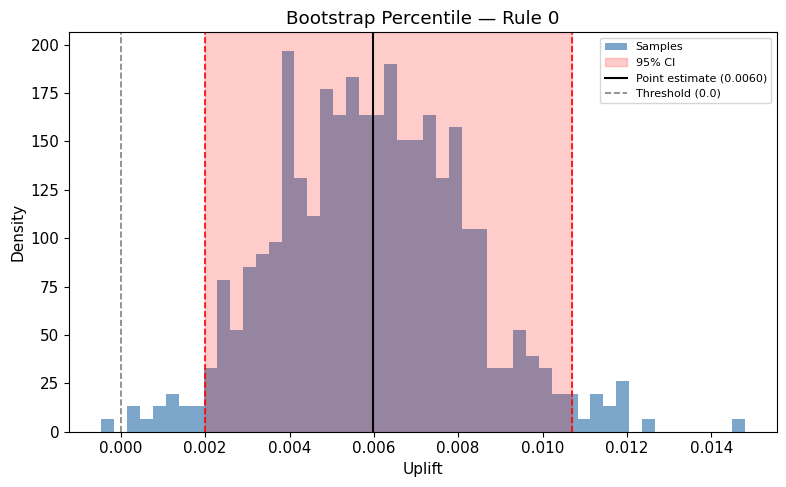

In [10]:
# 4.1 Bootstrap Percentile — empirical distribution of resampled uplifts
fig = bootstrap_histogram(results_boot[0], metric="uplift", threshold=0.0)
fig.axes[0].set_title("Bootstrap Percentile — Rule 0")
plt.tight_layout()

### 4.2 Bootstrap BCa Distribution

The BCa variant uses the same bootstrap resamples but applies bias-correction and acceleration. The CI endpoints shift to account for the skewness of the bootstrap distribution.

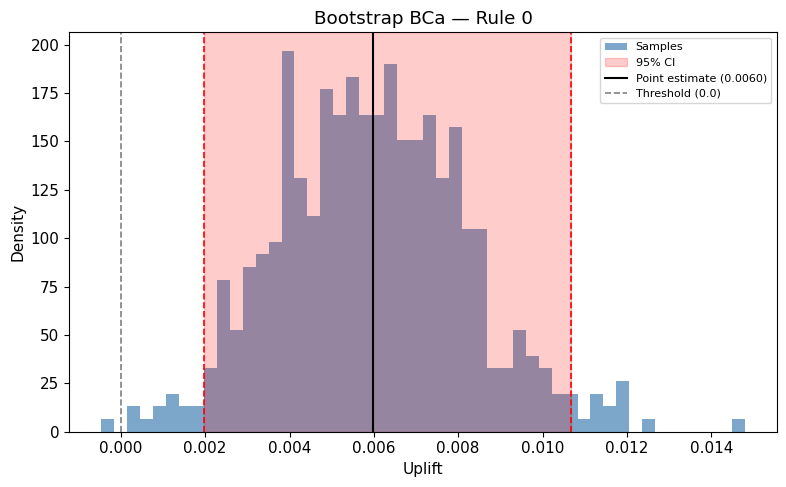

In [11]:
# 4.2 Bootstrap BCa — same resamples, but bias-corrected percentile endpoints
fig = bootstrap_histogram(results_bca[0], metric="uplift", threshold=0.0)
fig.axes[0].set_title("Bootstrap BCa — Rule 0")
plt.tight_layout()

### 4.3 Analytic Wald — Normal Distribution

The Wald method assumes the uplift is normally distributed with mean equal to the point estimate and standard deviation equal to the SE (from the delta method). Here we plot that implied normal distribution.

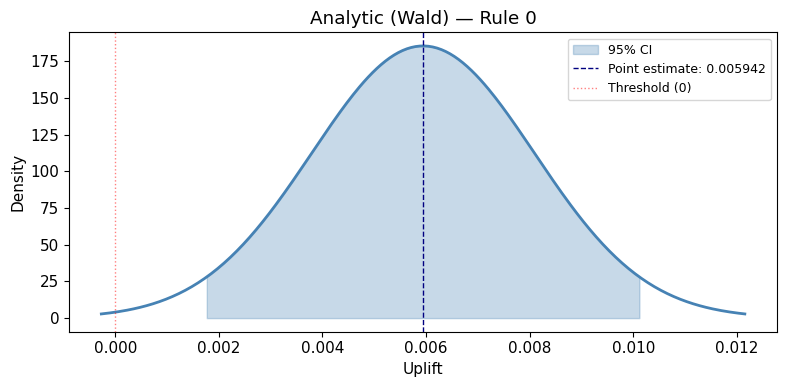

In [12]:
# 4.3 Analytic (Wald) — assumed normal distribution from point estimate and SE
from scipy.stats import norm as norm_dist

r_wald = results_anal[0]
x = np.linspace(r_wald.uplift_ci_lower - 0.002, r_wald.uplift_ci_upper + 0.002, 300)
y = norm_dist.pdf(x, loc=r_wald.uplift_point, scale=r_wald.uplift_se)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, color="steelblue", linewidth=2)
ax.fill_between(x, y, where=(x >= r_wald.uplift_ci_lower) & (x <= r_wald.uplift_ci_upper),
                alpha=0.3, color="steelblue", label="95% CI")
ax.axvline(r_wald.uplift_point, color="navy", linestyle="--", linewidth=1, label=f"Point estimate: {r_wald.uplift_point:.6f}")
ax.axvline(0.0, color="red", linestyle=":", linewidth=1, alpha=0.5, label="Threshold (0)")
ax.set_xlabel("Uplift")
ax.set_ylabel("Density")
ax.set_title("Analytic (Wald) — Rule 0")
ax.legend(fontsize=9)
plt.tight_layout()

### 4.4 Analytic Wilson — Normal Distribution

The Wilson interval uses a different point estimate (shrunk toward 0.5) and a slightly different SE. Here we plot the implied normal distribution using the Wilson point estimate and SE.

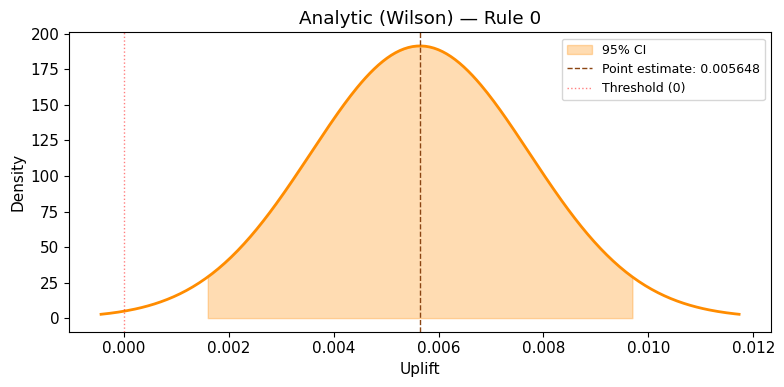

In [13]:
# 4.4 Analytic (Wilson) — adjusted normal distribution
r_wil = results_wilson[0]
x = np.linspace(r_wil.uplift_ci_lower - 0.002, r_wil.uplift_ci_upper + 0.002, 300)
y = norm_dist.pdf(x, loc=r_wil.uplift_point, scale=r_wil.uplift_se)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, color="darkorange", linewidth=2)
ax.fill_between(x, y, where=(x >= r_wil.uplift_ci_lower) & (x <= r_wil.uplift_ci_upper),
                alpha=0.3, color="darkorange", label="95% CI")
ax.axvline(r_wil.uplift_point, color="saddlebrown", linestyle="--", linewidth=1, label=f"Point estimate: {r_wil.uplift_point:.6f}")
ax.axvline(0.0, color="red", linestyle=":", linewidth=1, alpha=0.5, label="Threshold (0)")
ax.set_xlabel("Uplift")
ax.set_ylabel("Density")
ax.set_title("Analytic (Wilson) — Rule 0")
ax.legend(fontsize=9)
plt.tight_layout()

### 4.5 Bayesian Posterior Distribution

The Bayesian posterior shows the full probability distribution over the uplift parameter. Unlike the bootstrap histogram (which shows a sampling distribution), this directly represents our *belief* about the true uplift after observing the data.

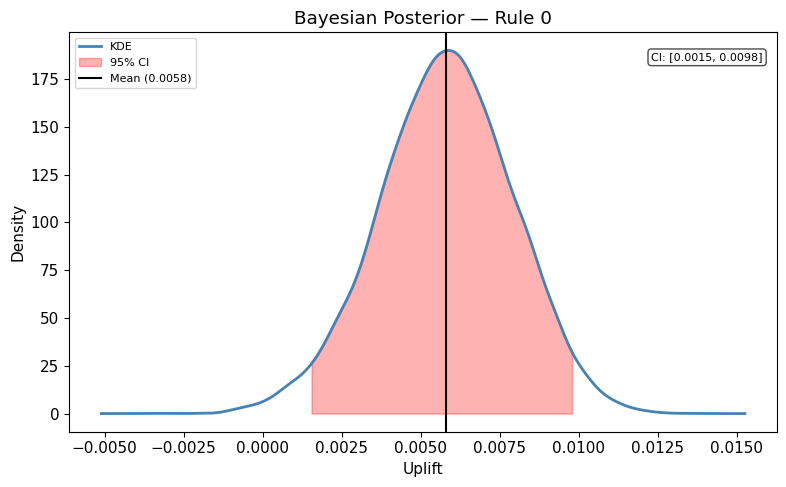

In [14]:
# 4.5 Bayesian — posterior distribution (KDE of Monte Carlo draws)
fig = posterior_plot(results_bayes[0], metric="uplift")
fig.axes[0].set_title("Bayesian Posterior — Rule 0")
plt.tight_layout()

### 4.6 All Five Methods — Overlay Comparison

Plotting all five distributions together reveals how each method characterises uncertainty for the same rule. Bootstrap and Bayesian show empirical shapes; Wald and Wilson overlay their implied normal curves.

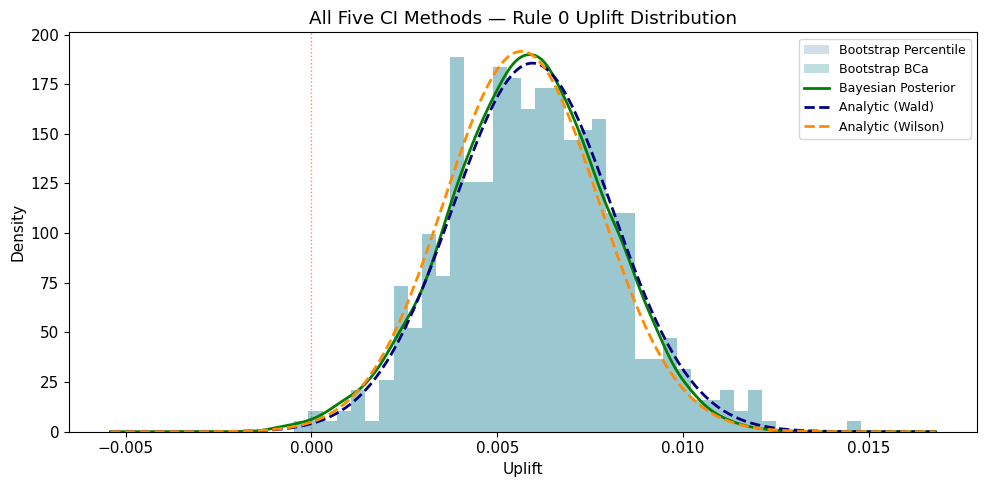

In [15]:
# 4.6 Overlay: all five distributions for Rule 0
fig, ax = plt.subplots(figsize=(10, 5))

# Bootstrap percentile histogram (normalized)
ax.hist(results_boot[0].samples_uplift, bins=40, density=True, alpha=0.25, color="steelblue", label="Bootstrap Percentile")

# Bootstrap BCa histogram (normalized)
ax.hist(results_bca[0].samples_uplift, bins=40, density=True, alpha=0.25, color="teal", label="Bootstrap BCa")

# Bayesian posterior KDE
from scipy.stats import gaussian_kde
kde = gaussian_kde(results_bayes[0].samples_uplift)
x_range = np.linspace(
    min(results_boot[0].samples_uplift.min(), results_bayes[0].samples_uplift.min()) - 0.002,
    max(results_boot[0].samples_uplift.max(), results_bayes[0].samples_uplift.max()) + 0.002,
    300,
)
ax.plot(x_range, kde(x_range), color="green", linewidth=2, label="Bayesian Posterior")

# Wald normal
r_w = results_anal[0]
ax.plot(x_range, norm_dist.pdf(x_range, loc=r_w.uplift_point, scale=r_w.uplift_se),
        color="navy", linewidth=2, linestyle="--", label="Analytic (Wald)")

# Wilson normal
r_ws = results_wilson[0]
ax.plot(x_range, norm_dist.pdf(x_range, loc=r_ws.uplift_point, scale=r_ws.uplift_se),
        color="darkorange", linewidth=2, linestyle="--", label="Analytic (Wilson)")

ax.axvline(0.0, color="red", linestyle=":", linewidth=1, alpha=0.5)
ax.set_xlabel("Uplift")
ax.set_ylabel("Density")
ax.set_title("All Five CI Methods — Rule 0 Uplift Distribution")
ax.legend(fontsize=9)
plt.tight_layout()

## 5. Forest Plots

### 5.1 Forest Plot (All Rules, Single Method)

A forest plot is the standard way to display multiple effect sizes with their confidence intervals. Each row is one rule, with a point estimate (dot) and error bars (CI). Rules are sorted by their point estimate. If a threshold is provided (vertical line), rules are color-coded:
- **Green** = Accept (entire CI above threshold)
- **Red** = Reject (entire CI below threshold)
- **Orange** = Uncertain (CI overlaps threshold)



In [16]:
# Forest plot with bootstrap CIs — threshold at 0 to see which rules have significant positive uplift
# show_categories=True adds Accept/Reject/Uncertain labels next to each rule
fig = forest_plot(results_boot, metric="uplift", threshold=0.0, show_categories=True)
plt.tight_layout()

### 5.2 Grouped Forest Plot (All Five Methods)

How do all five methods compare? The grouped forest plot overlays all five CIs for each rule. This is a powerful diagnostic: if the intervals are similar, we can trust the results. If they diverge, it suggests the sample size may be too small for the analytic approximation.



In [17]:
# Compare all five methods side by side
fig = grouped_forest_plot(
    {
        "Boot. Percentile": results_boot,
        "Boot. BCa": results_bca,
        "Analytic (Wald)": results_anal,
        "Analytic (Wilson)": results_wilson,
        "Bayesian": results_bayes,
    },
    metric="uplift",
    threshold=0.0,
)
plt.tight_layout()

## 6. Rule Categorization: Accept, Reject, or Uncertain

In practice, you want to decide: *should I deploy this rule or not?* The package provides automatic categorization based on a threshold:

- **Accept**: The *entire* CI is above the threshold — the rule is statistically significant.
- **Reject**: The *entire* CI is below the threshold — the rule is not effective.
- **Uncertain**: The CI *overlaps* the threshold — more data is needed to decide.

This is analogous to hypothesis testing, but instead of a binary p-value, you get a three-valued verdict that clearly communicates the decision-relevant uncertainty.

In [18]:
# Categorize rules: is the uplift significantly above 0?
results_categorized = ar.confidence_intervals(
    data,
    method="bootstrap",
    confidence_level=0.95,
    threshold=0.0,          # threshold for categorization
    metric="uplift",        # categorize based on uplift (or "realistic_rule_gain")
    n_bootstrap=500,
    random_state=42,
)

print(f"{'Rule':>6} | {'Uplift':>10} | {'95% CI':>24} | {'Category':>12}")
print("-" * 65)
for r in results_categorized:
    cat = r.category.value if r.category else "N/A"
    print(f"  {r.rule_index:>4} | {r.uplift_point:>10.6f} | [{r.uplift_ci_lower:>10.6f}, {r.uplift_ci_upper:>10.6f}] | {cat:>12}")

  Rule |     Uplift |                   95% CI |     Category
-----------------------------------------------------------------
     0 |   0.005977 | [  0.001989,   0.010695] |       accept
     1 |   0.004300 | [  0.001407,   0.007196] |       accept
     2 |   0.012664 | [  0.007113,   0.017681] |       accept
     3 |   0.008815 | [  0.005088,   0.011968] |       accept
     4 |   0.009427 | [  0.002305,   0.015421] |       accept
     5 |   0.006634 | [  0.002356,   0.010172] |       accept
     6 |   0.013325 | [  0.009063,   0.017273] |       accept
     7 |   0.009092 | [  0.006158,   0.011920] |       accept
     8 |   0.016382 | [  0.013489,   0.019452] |       accept
     9 |   0.011168 | [  0.008729,   0.013773] |       accept
    10 |   0.014316 | [  0.008638,   0.018174] |       accept
    11 |   0.009864 | [  0.006106,   0.013063] |       accept
    12 |   0.007463 | [  0.004168,   0.010673] |       accept
    13 |   0.005245 | [  0.002980,   0.007424] |       accept
    

## 7. Utility-Aware Confidence Intervals

Uplift tells us if a rule is *statistically* effective. But is it *economically* worthwhile? The **realistic rule gain** combines the statistical uplift with the utility tables to answer: *after accounting for the cost of the intervention and the value of the outcome, does this rule generate positive net value?*

A rule might have significant positive uplift but negative realistic gain — meaning the intervention costs more than the expected benefit.

In [19]:
# CI for realistic rule gain (economic value)
results_gain = ar.confidence_intervals(
    data,
    method="bootstrap",
    confidence_level=0.95,
    threshold=0.0,
    metric="realistic_rule_gain",
    n_bootstrap=500,
    random_state=42,
)

print(f"{'Rule':>6} | {'Gain':>10} | {'95% CI':>24} | {'Category':>12}")
print("-" * 65)
for r in results_gain:
    if r.realistic_rule_gain_point is not None:
        cat = r.category.value if r.category else "N/A"
        print(
            f"  {r.rule_index:>4} | {r.realistic_rule_gain_point:>10.2f} | "
            f"[{r.realistic_rule_gain_ci_lower:>10.2f}, {r.realistic_rule_gain_ci_upper:>10.2f}] | {cat:>12}"
        )

  Rule |       Gain |                   95% CI |     Category
-----------------------------------------------------------------
     0 |      88.07 | [     29.49,     156.30] |       accept
     1 |     102.26 | [     38.23,     164.86] |       accept
     2 |     175.54 | [     92.55,     243.61] |       accept
     3 |     193.71 | [    107.85,     258.85] |       accept
     4 |     118.75 | [     14.64,     204.59] |       accept
     5 |     138.62 | [     39.66,     218.02] |       accept
     6 |     181.35 | [    121.00,     233.19] |       accept
     7 |     197.61 | [    134.85,     249.80] |       accept
     8 |     214.05 | [    185.67,     243.65] |       accept
     9 |     230.23 | [    198.79,     267.34] |       accept
    10 |     176.62 | [     99.41,     226.46] |       accept
    11 |     197.41 | [    123.61,     254.09] |       accept
    12 |     110.03 | [     64.12,     152.02] |       accept
    13 |     123.84 | [     74.27,     166.30] |       accept
    



In [20]:
# Forest plot for realistic rule gain with category labels
# This clearly shows which rules are economically worthwhile (Accept),
# which are not (Reject), and which are ambiguous (Uncertain)
fig = forest_plot(results_gain, metric="realistic_rule_gain", threshold=0.0, show_categories=True)
plt.tight_layout()

### Bootstrap Distribution of Realistic Rule Gain (Single Rule)

Let's examine the gain distribution for one rule to see how uncertain the economic estimate is.

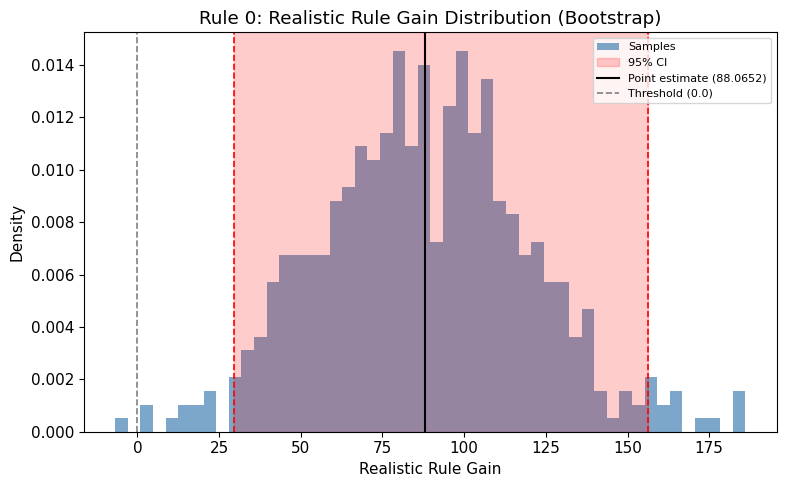

In [21]:
# Distribution of the realistic rule gain for the first rule
fig = bootstrap_histogram(results_gain[0], metric="realistic_rule_gain", threshold=0.0)
plt.tight_layout()

## 8. JSON Export with CI Data

After calling `confidence_intervals()`, the CI data is automatically included in the JSON export. This makes it easy to consume the results in downstream systems (dashboards, APIs, reports).

In [22]:
import json

# The export now includes a "ci" key for each rule
export = json.loads(rules.get_export_notation())

# Pretty-print the first rule
print(json.dumps(export[0], indent=2))

{
  "stable": [
    {
      "attribute": "gender",
      "value": "Female"
    },
    {
      "attribute": "SeniorCitizen",
      "value": "0"
    },
    {
      "attribute": "Partner",
      "value": "No"
    },
    {
      "attribute": "OnlineSecurity",
      "value": "No",
      "flexible_as_stable": true
    },
    {
      "attribute": "DeviceProtection",
      "value": "No",
      "flexible_as_stable": true
    },
    {
      "attribute": "StreamingTV",
      "value": "No",
      "flexible_as_stable": true
    }
  ],
  "flexible": [
    {
      "attribute": "PhoneService",
      "undesired": "Yes",
      "desired": "No"
    },
    {
      "attribute": "InternetService",
      "undesired": "Fiber optic",
      "desired": "DSL"
    }
  ],
  "target": {
    "attribute": "Churn",
    "undesired": "Yes",
    "desired": "No"
  },
  "support of undesired part": 115,
  "confidence of undesired part": 0.6020942408376964,
  "support of desired part": 29,
  "confidence of desired part": 0.61

## 9. Comparing All Five Methods on Realistic Rule Gain

Let's see how bootstrap, analytic, and Bayesian methods compare for the economic metric. This is useful for validation: if all three methods agree, you can be more confident in the result.



In [23]:
# Compute CIs for realistic_rule_gain with all five methods
gain_boot = ar.confidence_intervals(data, method="bootstrap", n_bootstrap=500, random_state=42)
gain_bca = ar.confidence_intervals(data, method="bootstrap", n_bootstrap=500, random_state=42, bootstrap_type="bca")
gain_anal = ar.confidence_intervals(data, method="analytic")
gain_wilson = ar.confidence_intervals(data, method="analytic", analytic_type="wilson")
gain_bayes = ar.confidence_intervals(data, method="bayesian", n_mc=10000, random_state=42)

# Grouped forest plot for realistic rule gain
fig = grouped_forest_plot(
    {
        "Boot. Percentile": gain_boot,
        "Boot. BCa": gain_bca,
        "Analytic (Wald)": gain_anal,
        "Analytic (Wilson)": gain_wilson,
        "Bayesian": gain_bayes,
    },
    metric="realistic_rule_gain",
    threshold=0.0,
)
plt.tight_layout()

## 10. Side-by-Side Comparison Table

Let's build a summary table comparing all three methods for each rule. This is the kind of table you might include in a report or paper.

In [24]:
# Build a comparison DataFrame for all five methods
rows = []
for method_name, results in [
    ("Boot. Percentile", results_boot),
    ("Boot. BCa", results_bca),
    ("Analytic (Wald)", results_anal),
    ("Analytic (Wilson)", results_wilson),
    ("Bayesian", results_bayes),
]:
    for r in results:
        rows.append({
            "Rule": r.rule_index,
            "Method": method_name,
            "Uplift": round(r.uplift_point, 6),
            "CI Lower": round(r.uplift_ci_lower, 6),
            "CI Upper": round(r.uplift_ci_upper, 6),
            "SE": round(r.uplift_se, 6),
            "CI Width": round(r.uplift_ci_upper - r.uplift_ci_lower, 6),
        })

comparison_df = pd.DataFrame(rows)
comparison_df = comparison_df.sort_values(["Rule", "Method"]).reset_index(drop=True)
print(f"Comparison table: {len(comparison_df)} rows ({len(results_boot)} rules x 5 methods)")
comparison_df.head(15)

Comparison table: 2825 rows (565 rules x 5 methods)


,Rule,Method,Uplift,CI Lower,CI Upper,SE,CI Width
0,0,Analytic (Wald),0.005942,0.001729,0.010155,0.002149,0.008426
1,0,Analytic (Wilson),0.005648,0.001566,0.009730,0.002083,0.008165
2,0,Bayesian,0.005792,0.001509,0.009809,0.002110,0.008301
3,0,Boot. BCa,0.005977,0.001963,0.010675,0.002243,0.008712
4,0,Boot. Percentile,0.005977,0.001989,0.010695,0.002243,0.008706
5,1,Analytic (Wald),0.004332,0.001464,0.007200,0.001463,0.005737
6,1,Analytic (Wilson),0.004108,0.001327,0.006890,0.001419,0.005563
7,1,Bayesian,0.004220,0.001307,0.007016,0.001448,0.005708
8,1,Boot. BCa,0.004300,0.001572,0.007451,0.001534,0.005879
9,1,Boot. Percentile,0.004300,0.001407,0.007196,0.001534,0.005788


## 11. Working with the `ConfidenceIntervalResult` Object

Each result is a `ConfidenceIntervalResult` dataclass with all the information you need for further analysis. Here's a quick reference of available fields.

In [25]:
# Inspect the first result object
r = results_boot[0]
print(f"Rule index:       {r.rule_index}")
print(f"Method:           {r.method}")
print(f"Confidence level: {r.confidence_level}")
print()
print(f"Uplift point:     {r.uplift_point:.6f}")
print(f"Uplift CI:        [{r.uplift_ci_lower:.6f}, {r.uplift_ci_upper:.6f}]")
print(f"Uplift SE:        {r.uplift_se:.6f}")
print()
if r.realistic_rule_gain_point is not None:
    print(f"Gain point:       {r.realistic_rule_gain_point:.2f}")
    print(f"Gain CI:          [{r.realistic_rule_gain_ci_lower:.2f}, {r.realistic_rule_gain_ci_upper:.2f}]")
    print(f"Gain SE:          {r.realistic_rule_gain_se:.2f}")
    print()
print(f"Support:          {r.support}")
print(f"Confidence:       {r.confidence:.4f}")
print(f"Category:         {r.category}")
print()
print(f"Bootstrap samples available: {r.samples_uplift is not None}")
if r.samples_uplift is not None:
    print(f"Number of samples: {len(r.samples_uplift)}")

Rule index:       0
Method:           bootstrap
Confidence level: 0.95

Uplift point:     0.005977
Uplift CI:        [0.001989, 0.010695]
Uplift SE:        0.002243

Gain point:       88.07
Gain CI:          [29.49, 156.30]
Gain SE:          31.97

Support:          191
Confidence:       0.6021
Category:         RuleCategory.ACCEPT

Bootstrap samples available: True
Number of samples: 500


## 12. Quick Reference

### Python API

```python
from action_rules import ActionRules

ar = ActionRules(...)
ar.fit(data, ...)

# Compute CIs (any method)
results = ar.confidence_intervals(
    data,
    method="bootstrap",       # "bootstrap", "bca", "analytic", "wald", "wald_rd", "clopper_pearson", "bayesian", "jeffreys", or "honest_split"
    confidence_level=0.95,
    threshold=0.0,
    metric="uplift",
    n_bootstrap=1000,         # bootstrap only
    n_mc=10000,               # bayesian only
    random_state=42,
    analytic_type="wald",     # "wald", "wald_rd", "newcombe_wilson" ("wilson"), "clopper_pearson", or "auto" (analytic only)
    bootstrap_type="percentile",  # "percentile" or "bca" (bootstrap only)
    prior=None,               # "uniform", "jeffreys", or "haldane" (bayesian only)
    simultaneous_m=None,      # optional Bonferroni multiplicity count (analytic only)
    resample_mode="rows",     # "rows" or "multinomial" (bootstrap only)
)
```

### Visualization

```python
from action_rules.visualization import (
    bootstrap_histogram,   # single-rule distribution (bootstrap or bayesian)
    posterior_plot,         # single-rule KDE posterior (bayesian)
    forest_plot,           # all rules, one method
    grouped_forest_plot,   # all rules, multiple methods overlaid
)

# All functions accept metric="uplift" or metric="realistic_rule_gain"
# All return a matplotlib Figure object
```

### CLI

```bash
action-rules --csv_path data.csv ... --ci_method bootstrap --confidence_level 0.95 \
    --n_bootstrap 1000 --ci_threshold 0.0 --random_state 42 --output_json_path rules.json
```

### Installation

```bash
pip install action-rules              # core package
pip install action-rules[inference]   # + scipy (for analytic/bayesian CI)
pip install action-rules[viz]         # + scipy + matplotlib (for plots)
```